# **ML Assignment 5**

**Download dataset and import libraries**

In [4]:
%pip -q install kagglehub

import kagglehub, glob, os
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

path = kagglehub.dataset_download("kyanyoga/sample-sales-data")
files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)

file = next(f for f in files if "sales_data_sample" in f.lower())

df = pd.read_csv(file, encoding="latin1")

print(df.head())
print("Dataset shape:", df.shape)

Using Colab cache for faster access to the 'sample-sales-data' dataset.
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           Na

**Select features and scale data**

In [5]:
X = df[["SALES", "QUANTITYORDERED", "PRICEEACH"]].dropna()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data prepared:", X_scaled.shape)

Data prepared: (2823, 3)


**Find the optimal clusters using the Elbow Method**

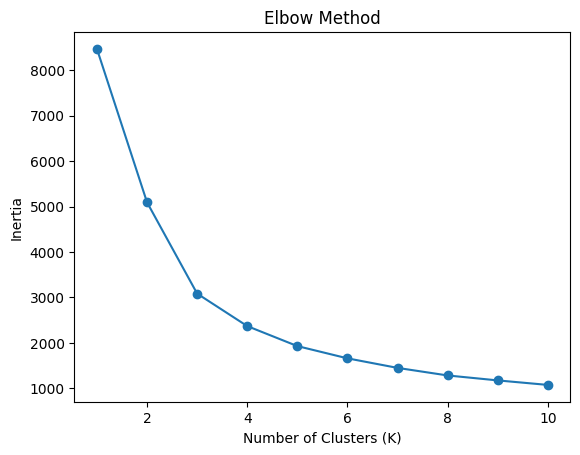

In [6]:
inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

**Apply K-Means and visualize clusters**

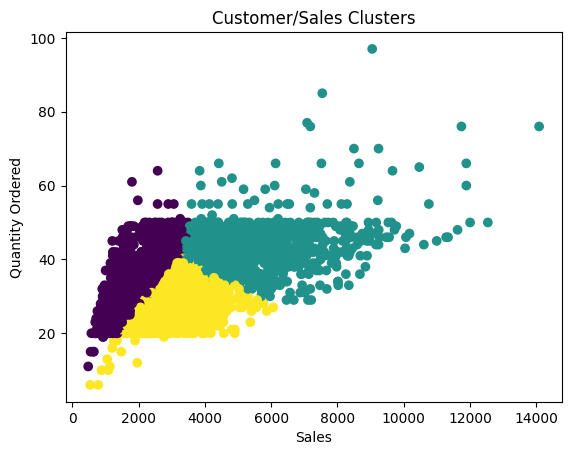

     SALES  QUANTITYORDERED  Cluster
0  2871.00               30        2
1  2765.90               34        2
2  3884.34               41        1
3  3746.70               45        1
4  5205.27               49        1


In [7]:
k = 3

model = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = model.fit_predict(X_scaled)

result = df.loc[X.index].copy()
result["Cluster"] = clusters

plt.scatter(result["SALES"], result["QUANTITYORDERED"],
            c=clusters, cmap="viridis")
plt.xlabel("Sales")
plt.ylabel("Quantity Ordered")
plt.title("Customer/Sales Clusters")
plt.show()

print(result[["SALES", "QUANTITYORDERED", "Cluster"]].head())